This script demonstrates how to perform exploratory data analysis on financial transaction data, with a focus on anti-money laundering (AML) concepts.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

# Get data

In [2]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/data?select=HI-Small_accounts.csv
    
# load transaction and account datasets
transactions = pd.read_csv(
    data_dir / 'HI-Small_Trans.csv',
    encoding='Latin-1',
    low_memory=False
)

# convert timestamp to datetime
transactions['Timestamp'] = pd.to_datetime(transactions['Timestamp'])
transactions['transaction_date'] = transactions['Timestamp'].dt.date

transactions = transactions.loc[
    transactions['Timestamp'] < '2022-09-11'
].copy()
transactions.reset_index(drop=True, inplace=True)

accounts = pd.read_csv(
    data_dir / 'HI-Small_accounts.csv',
    encoding='Latin-1',
    low_memory=False
)

In [3]:
# inspect transaction date range
print("date range:")
print(transactions['Timestamp'].min())
print(transactions['Timestamp'].max())

date range:
2022-09-01 00:00:00
2022-09-10 23:59:00


In [4]:
transactions.groupby(['transaction_date', 'Is Laundering']).size()

transaction_date  Is Laundering
2022-09-01        0                1114599
                  1                    322
2022-09-02        0                 754041
                  1                    408
2022-09-03        0                 206991
                  1                    391
2022-09-04        0                 207023
                  1                    407
2022-09-05        0                 482179
                  1                    471
2022-09-06        0                 481558
                  1                    531
2022-09-07        0                 482254
                  1                    497
2022-09-08        0                 482234
                  1                    539
2022-09-09        0                 653953
                  1                    514
2022-09-10        0                 207883
                  1                    442
dtype: int64

# Explore data

## Clean and wrangle

In [5]:
# inspect dataset dimensions
print("transactions:", transactions.shape)
print("accounts:", accounts.shape)

# inspect column names and data types
print("\ntransaction columns:")
print(transactions.dtypes)

print("\naccount columns:")
print(accounts.dtypes)

# preview records
display(transactions.head())
display(accounts.head())

transactions: (5077237, 12)
accounts: (518581, 5)

transaction columns:
Timestamp             datetime64[us]
From Bank                      int64
Account                          str
To Bank                        int64
Account.1                        str
Amount Received              float64
Receiving Currency               str
Amount Paid                  float64
Payment Currency                 str
Payment Format                   str
Is Laundering                  int64
transaction_date              object
dtype: object

account columns:
Bank Name           str
Bank ID           int64
Account Number      str
Entity ID           str
Entity Name         str
dtype: object


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,transaction_date
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0,2022-09-01
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0,2022-09-01
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0,2022-09-01
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0,2022-09-01
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0,2022-09-01


,Bank Name,Bank ID,Account Number,Entity ID,Entity Name
0,Portugal Bank #4507,331579,80B779D80,80062E240,Sole Proprietorship #50438
1,Canada Bank #27,210,809D86900,800C998A0,Corporation #33520
2,UK Bank #33,21884,80812BE00,800C47F50,Partnership #35397
3,Germany Bank #4815,32742,81047F300,80096F0B0,Corporation #48813
4,National Bank of Harrisburg,127390,80BD8CF00,800FB8760,Corporation #889


In [6]:
len(transactions)

5077237

In [7]:
# inspect missing values
print("transaction missing values:")
display(transactions.isnull().sum())

print("\naccount missing values:")
display(accounts.isnull().sum())

# inspect duplicate records
print("\ntransaction duplicates:", transactions.duplicated().sum())
print("\naccount duplicates:", accounts.duplicated().sum())

transaction missing values:


Timestamp             0
From Bank             0
Account               0
To Bank               0
Account.1             0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
transaction_date      0
dtype: int64

account missing values:


Bank Name         0
Bank ID           0
Account Number    0
Entity ID         0
Entity Name       0
dtype: int64

transaction duplicates: 9
account duplicates: 0


## Explore class imbalance

In [7]:
# inspect target distribution
print("\nlaundering distribution:")
display(transactions['Is Laundering'].value_counts())

# inspect target proportions
display(
    transactions['Is Laundering']
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

print("""
Note the extreme class imbalance of the IsLaundering values.  
This is typical of AML data, and it will need to be considered downstream during modeling.
""")


laundering distribution:


Is Laundering
0    5072715
1       4522
Name: count, dtype: int64

Is Laundering
0    99.9109
1     0.0891
Name: proportion, dtype: float64


Note the extreme class imbalance of the IsLaundering values.  
This is typical of AML data, and it will need to be considered downstream during modeling.



## Explore laundering

### Daily laundering count

In [9]:
# examine laundering distribution over time
daily_laundering = (
    transactions
    .set_index('Timestamp')
    .resample('D')['Is Laundering']
    .agg(['count', 'sum'])
)

daily_laundering['laundering_rate'] = (
    daily_laundering['sum'] / daily_laundering['count'] * 100
)

display(daily_laundering.describe())

,count,sum,laundering_rate
count,1.000000e+01,10.000000,10.000000
mean,5.077237e+05,452.200000,0.118075
std,2.835585e+05,70.491607,0.061726
min,2.073820e+05,322.000000,0.028881
25%,2.767660e+05,407.250000,0.083299
50%,4.827005e+05,456.500000,0.106549
75%,6.115435e+05,509.750000,0.169317
max,1.114921e+06,539.000000,0.212168


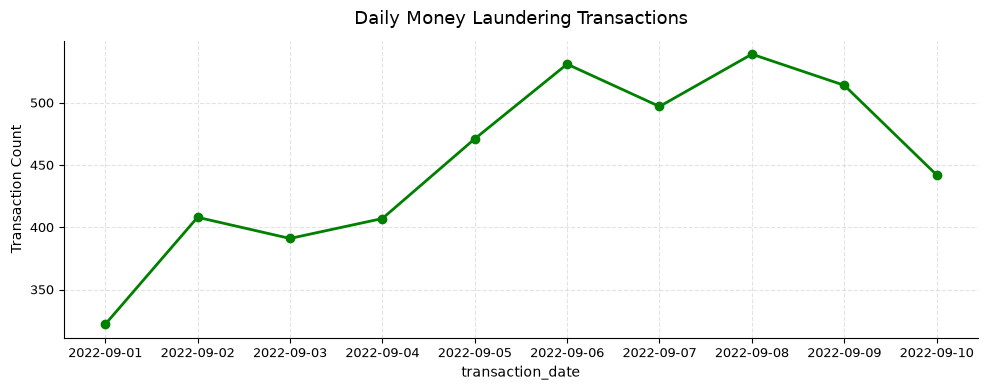

Obviously the chart shows an increasing trend in daily laundering transactions.


In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    daily_laundering.index,
    daily_laundering['sum'],
    color='green',
    linewidth=2,
    marker='o'
)

ax.set_title('Daily Money Laundering Transactions', fontsize=13, pad=12)
ax.set_xlabel('transaction_date', fontsize=10)
ax.set_ylabel('Transaction Count', fontsize=10)

ax.grid(True, linestyle='--', alpha=0.35)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.show()

print('Obviously the chart shows an increasing trend in daily laundering transactions.')

### Transaction amount

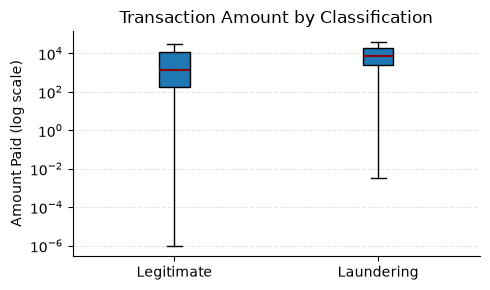

It's interesting that the relative maxes and means are similar,
despite the wider range of Legit transactions.


In [11]:
fig, ax = plt.subplots(figsize=(5, 3))

amounts = [
    transactions.loc[transactions['Is Laundering'] == 0, 'Amount Paid'],
    transactions.loc[transactions['Is Laundering'] == 1, 'Amount Paid']
]

ax.boxplot(
    amounts,
    tick_labels=['Legitimate', 'Laundering'],
    showfliers=False,
    patch_artist=True,
    medianprops=dict(color='darkred', linewidth=1.5),
)

ax.set_yscale('log')
ax.set_title('Transaction Amount by Classification', fontsize=12)
ax.set_ylabel('Amount Paid (log scale)')
ax.grid(axis='y', linestyle='--', alpha=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("""It's interesting that the relative maxes and means are similar,
despite the wider range of Legit transactions.""")

### Payment format

In [12]:
payment_analysis = (
    transactions.groupby('Payment Format')
    .agg(
        transaction_count=('Is Laundering', 'count'),
        laundering_count=('Is Laundering', 'sum')
    )
)

payment_analysis['laundering_rate (%)'] = (
    payment_analysis['laundering_count'] /
    payment_analysis['transaction_count'] * 100
)

payment_analysis = payment_analysis.sort_values(
    'laundering_rate (%)', ascending=False
)

display(payment_analysis)

# ACH (Automated Clearing House): Electronic bank-to-bank transfers, 
    # commonly used for payroll, bill payments, and direct deposits.
# Bitcoin: Cryptocurrency transactions conducted over the Bitcoin network.
# Cash: Physical currency payments or transfers.
# Cheque: Paper checks used to transfer funds between accounts.
# Credit Card: Payments made using a credit card, typically processed through a card network.
# Reinvestment: Funds reinvested rather than withdrawn or transferred out, such as investment proceeds.
# Wire: Direct electronic transfers between financial institutions,
    # often used for larger or international payments.
    
print("""
Note how ACH is the dominating proportion for money laundering by transaction count.
""")

,transaction_count,laundering_count,laundering_rate (%)
Payment Format,,,
ACH,599689,3828,0.638331
Bitcoin,146091,56,0.038332
Cash,490891,108,0.022001
Cheque,1864331,324,0.017379
Credit Card,1323324,206,0.015567
Reinvestment,481056,0,0.000000
Wire,171855,0,0.000000



Note how ACH is the dominating proportion for money laundering by transaction count.



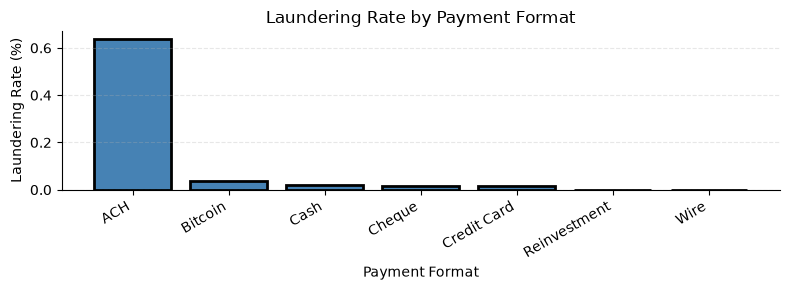

In [13]:
fig, ax = plt.subplots(figsize=(8, 3))

ax.bar(
    payment_analysis.index,
    payment_analysis['laundering_rate (%)'],
    color='steelblue',
    edgecolor='black',
    lw=2
)

ax.set_title('Laundering Rate by Payment Format', fontsize=12)
ax.set_xlabel('Payment Format')
ax.set_ylabel('Laundering Rate (%)')
ax.grid(axis='y', linestyle='--', alpha=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### Daily laundering proportion

In [14]:
# aggregate transactions by day
daily_activity = (
    transactions
    .set_index('Timestamp')
    .resample('D')
    .agg(
        transaction_count=('Is Laundering', 'count'),
        laundering_count=('Is Laundering', 'sum')
    )
)

# calculate daily laundering rate
daily_activity['laundering_rate (%)'] = (
    daily_activity['laundering_count']
    / daily_activity['transaction_count'] * 100
)

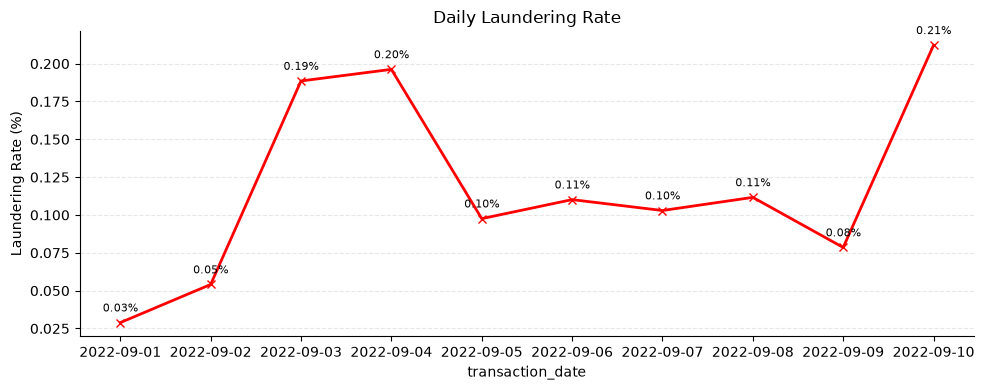


Check out the IsLaundering transaction count chart a few sections above.
It shows an increasing trend in transaction counts, but here we see the percentage of those IsLaundering
attempts actually stays between two bands of values.



In [15]:
# plot daily laundering rate
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    daily_activity.index,
    daily_activity['laundering_rate (%)'],
    color='red',
    marker='x',
    linewidth=2
)

# annotate percentages above markers
for x, y in zip(daily_activity.index, daily_activity['laundering_rate (%)']):
    ax.annotate(
        f'{y:.2f}%',
        (x, y),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center',
        fontsize=8
    )

ax.set_title('Daily Laundering Rate', fontsize=12)
ax.set_xlabel('transaction_date')
ax.set_ylabel('Laundering Rate (%)')
ax.grid(axis='y', linestyle='--', alpha=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("""
Check out the IsLaundering transaction count chart a few sections above.
It shows an increasing trend in transaction counts, but here we see the percentage of those IsLaundering
attempts actually stays between two bands of values.
""")

### Paid vs received

In [16]:
# explore paid vs received
transactions['amount_difference'] = (
    transactions['Amount Paid'] - transactions['Amount Received']
)

transactions['amount_difference_pct'] = (
    transactions['amount_difference'] /
    transactions['Amount Paid'].replace(0, np.nan) * 100
)

amount_comparison = (
    transactions.groupby('Is Laundering')
    [['Amount Paid', 'Amount Received', 'amount_difference_pct']]
    .median()
)

amount_comparison.index = ['Legitimate', 'Laundering']

amount_comparison.round(2)

,Amount Paid,Amount Received,amount_difference_pct
Legitimate,1410.61,1407.16,0.0
Laundering,7707.64,7707.64,0.0


### Account activity

In [17]:
# explore transaction frequency by account
# this is an important AML feature because unusual transaction volume or rapid movement of funds can be suspicious

account_activity = (
    transactions.groupby('Account')
    .agg(
        transaction_count=('Is Laundering', 'count'),
        total_amount=('Amount Paid', 'sum'),
        avg_amount=('Amount Paid', 'mean'),
        laundering_count=('Is Laundering', 'sum')
    )
)

account_activity['laundering_rate (%)'] = (
    account_activity['laundering_count'] /
    account_activity['transaction_count'] * 100
)

account_activity.sort_values(
    'transaction_count', ascending=False
).head(10)

,transaction_count,total_amount,avg_amount,laundering_count,laundering_rate (%)
Account,,,,,
100428660,168672,5.276229e+10,3.128100e+05,243,0.144067
1004286A8,103018,2.606938e+10,2.530565e+05,158,0.153371
100428978,20497,7.532110e+09,3.674738e+05,29,0.141484
1004286F0,18663,2.465736e+10,1.321189e+06,21,0.112522
100428780,17264,3.739337e+11,2.165974e+07,21,0.121640
1004289C0,16794,1.051719e+10,6.262469e+05,13,0.077409
100428810,16426,5.153616e+09,3.137475e+05,26,0.158286
1004287C8,14174,1.011072e+11,7.133289e+06,16,0.112883
100428738,13756,2.592168e+11,1.884391e+07,23,0.167200


### Transaction velocity by account
In banking and AML, velocity refers to the frequency and speed of financial transactions over a given period

In [18]:
daily_account_activity = (
    transactions.groupby(['Account', 'transaction_date'])
    .size()
    .reset_index(name='daily_transaction_count')
)

account_velocity = (
    daily_account_activity.groupby('Account')
    .agg(
        avg_daily_transactions=('daily_transaction_count', 'mean'),
        max_daily_transactions=('daily_transaction_count', 'max'),
        active_days=('transaction_date', 'nunique')
    )
    .sort_values('max_daily_transactions', ascending=False)
)

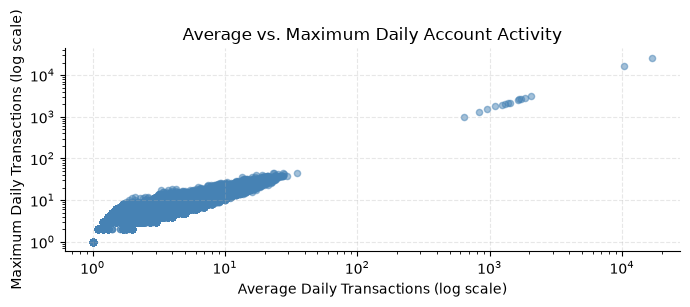


The chart shows a clear trend and grouping of data.
The extreme values could be real or only outliers.



In [19]:
fig, ax = plt.subplots(figsize=(7, 3))

account_plot = account_velocity.loc[
    account_velocity['active_days'] >= 10
].copy()

ax.scatter(
    account_plot['avg_daily_transactions'],
    account_plot['max_daily_transactions'],
    color='steelblue',
    alpha=0.5,
    s=20
)

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_title('Average vs. Maximum Daily Account Activity')
ax.set_xlabel('Average Daily Transactions (log scale)')
ax.set_ylabel('Maximum Daily Transactions (log scale)')
ax.grid(linestyle='--', alpha=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("""
The chart shows a clear trend and grouping of data.
The extreme values could be real or only outliers.
""")

### Counterparty diversity
How many unique recipients each account sends money to.  
Another useful AML behavioral feature.  
An account rapidly sending funds to many different recipients may warrant closer examination.

In [20]:
account_counterparties = (
    transactions.groupby(['Account', 'Is Laundering'])
    .agg(
        unique_recipients=('Account.1', 'nunique'),
        unique_banks=('To Bank', 'nunique'),
        transaction_count=('Account.1', 'count')
    )
    .reset_index()
)

account_counterparties['recipient_ratio (%)'] = (
    account_counterparties['unique_recipients'] /
    account_counterparties['transaction_count'] * 100
)

account_counterparties = account_counterparties.sort_values(
    'unique_recipients', ascending=False
)

account_counterparties.head()

,Account,Is Laundering,unique_recipients,unique_banks,transaction_count,recipient_ratio (%)
0,100428660,0,14230,618,168429,8.448664
2,1004286A8,0,8846,393,102860,8.600039
22,100428978,0,1775,78,20468,8.672073
4,1004286F0,0,1575,87,18642,8.448664
24,1004289C0,0,1432,67,16781,8.533460


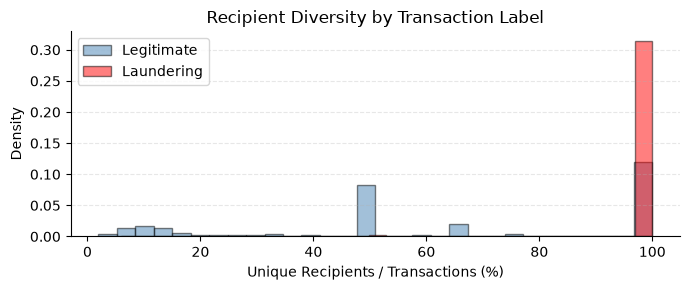


Clearly laundering forms a distinct group of behavior.
Zooming in shows other small laundering activities, but none like this.



In [21]:
fig, ax = plt.subplots(figsize=(7, 3))

for label, color, name in [
    (0, 'steelblue', 'Legitimate'),
    (1, 'red', 'Laundering')
]:
    ax.hist(
        account_counterparties.loc[
            account_counterparties['Is Laundering'] == label,
            'recipient_ratio (%)'
        ],
        bins=30,
        alpha=0.5,
        density=True,
        color=color,
        label=name,
        edgecolor='black'
    )

ax.set_title('Recipient Diversity by Transaction Label')
ax.set_xlabel('Unique Recipients / Transactions (%)')
ax.set_ylabel('Density')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend()
#plt.ylim(0,0.09)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("""
Clearly, laundering forms a distinct group of behavior.
Zooming in shows other small laundering activities, but none like this.
""")

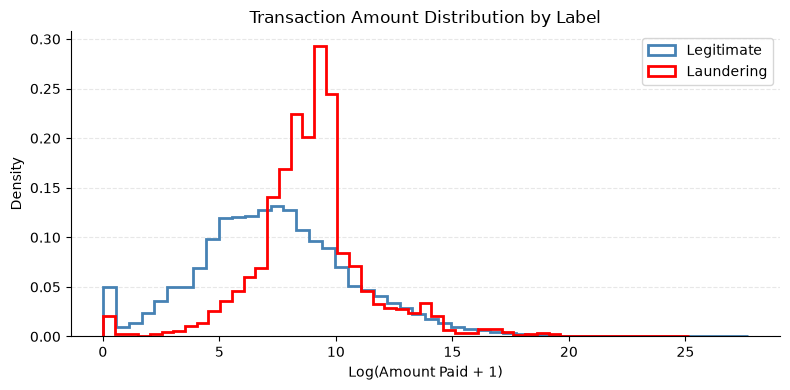


A spike in the laundering distribution suggests that laundering transactions are concentrated around 
certain transaction amounts.



In [22]:
fig, ax = plt.subplots(figsize=(8, 4))

for label, color, name in [
    (0, 'steelblue', 'Legitimate'),
    (1, 'red', 'Laundering')
]:
    values = transactions.loc[
        transactions['Is Laundering'] == label,
        'Amount Paid'
    ]

    ax.hist(
        np.log1p(values),
        bins=50,
        density=True,
        histtype='step',
        linewidth=2,
        color=color,
        label=name
    )

ax.set_title('Transaction Amount Distribution by Label')
ax.set_xlabel('Log(Amount Paid + 1)')
ax.set_ylabel('Density')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("""
A spike in the laundering distribution suggests that laundering transactions are concentrated around 
certain transaction amounts.
""")

### Transaction timing

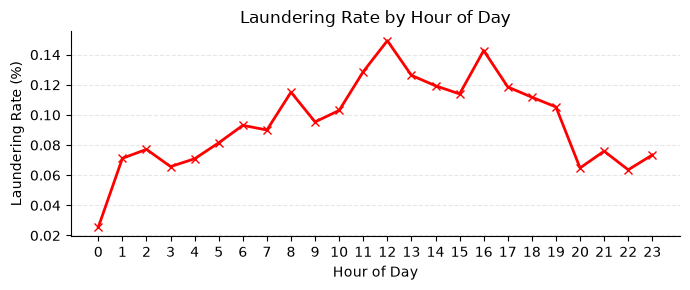


A clear cluster resides near from noon until 8PM.



In [23]:
transactions['hour'] = transactions['Timestamp'].dt.hour

hourly_activity = (
    transactions.groupby(['hour', 'Is Laundering'])
    .size()
    .unstack(fill_value=0)
)

hourly_rate = (
    hourly_activity[1] /
    hourly_activity.sum(axis=1) * 100
)

fig, ax = plt.subplots(figsize=(7, 3))

ax.plot(
    hourly_rate.index,
    hourly_rate.values,
    color='red',
    marker='x',
    linewidth=2
)

ax.set_title('Laundering Rate by Hour of Day')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Laundering Rate (%)')
ax.set_xticks(range(0, 24))
ax.grid(axis='y', linestyle='--', alpha=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("""
A clear cluster resides near from noon until 8PM.
""")

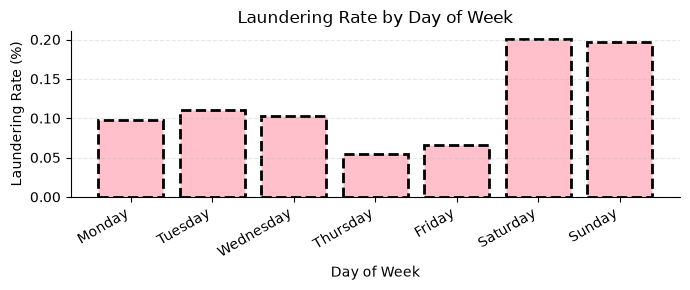

In [24]:
transactions['day_of_week'] = (
    transactions['Timestamp'].dt.day_name()
)

weekday_activity = (
    transactions.groupby(['day_of_week', 'Is Laundering'])
    .size()
    .unstack(fill_value=0)
)

weekday_activity['laundering_rate (%)'] = (
    weekday_activity[1] /
    weekday_activity.sum(axis=1) * 100
)

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

weekday_activity = weekday_activity.reindex(weekday_order)

fig, ax = plt.subplots(figsize=(7, 3))

ax.bar(
    weekday_activity.index,
    weekday_activity['laundering_rate (%)'],
    color='pink',
    edgecolor='black',
    lw=2,
    ls='--'
)

ax.set_title('Laundering Rate by Day of Week')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Laundering Rate (%)')
ax.grid(axis='y', linestyle='--', alpha=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

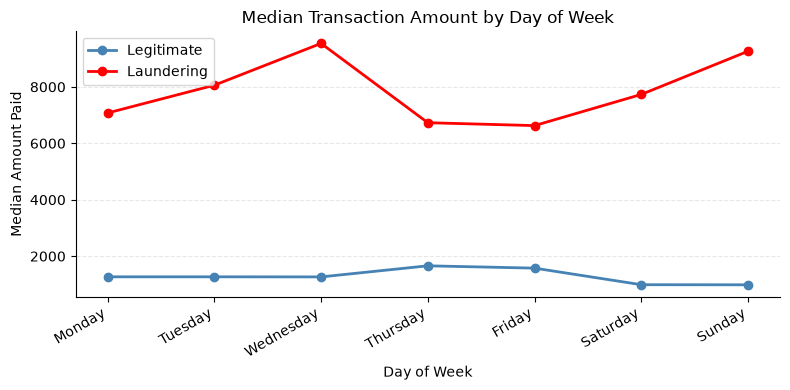


Hmmm...on the weekends, a larger pecentage of transactions are laundering.
But, Wednesdays hold the highest laundering median.
This could be a true signal, like a single transaction, or it could be noise.



In [25]:
fig, ax = plt.subplots(figsize=(8, 4))

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

for label, color, name in [
    (0, 'steelblue', 'Legitimate'),
    (1, 'red', 'Laundering')
]:
    values = transactions.loc[
        transactions['Is Laundering'] == label
    ].groupby('day_of_week')['Amount Paid'].median()

    ax.plot(
        weekday_order,
        values.reindex(weekday_order),
        marker='o',
        linewidth=2,
        color=color,
        label=name
    )

ax.set_title('Median Transaction Amount by Day of Week')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Median Amount Paid')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print("""
Hmmm...on the weekends, a larger pecentage of transactions are laundering.
But, Wednesdays hold the highest laundering median.
This could be a true signal, like a single transaction, or it could be noise.
""")

# Feature engineering
For downstream modeling

In [26]:
model_df = transactions.copy()

# Transaction amount relationship
model_df['amount_difference'] = (
    model_df['Amount Paid'] - model_df['Amount Received']
)

# Transaction timing
model_df['hour'] = model_df['Timestamp'].dt.hour
model_df['day_of_week'] = model_df['Timestamp'].dt.dayofweek
model_df['is_weekend'] = (
    model_df['day_of_week'] >= 5
).astype(int)

# Transaction characteristics
model_df['amount_paid_log'] = np.log1p(model_df['Amount Paid'])
model_df['amount_received_log'] = np.log1p(model_df['Amount Received'])

# Payment currency relationship
model_df['same_currency'] = (
    model_df['Payment Currency'] ==
    model_df['Receiving Currency']
).astype(int)

model_df.head()

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,transaction_date,amount_difference,amount_difference_pct,hour,day_of_week,is_weekend,amount_paid_log,amount_received_log,same_currency
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,8.215639,8.215639,1
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0,2022-09-01,0.0,0.0,0,3,0,0.009950,0.009950,1
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,9.594008,9.594008,1
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,7.940217,7.940217,1
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,10.510095,10.510095,1


# Write

In [ ]:
model_df.to_csv(
    data_dir / 'aml_model_data.csv',
    index=False
)

In [28]:
print('done')

done
